## **Importing Libraries**

In [1]:
import os 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from warnings import filterwarnings
filterwarnings('ignore') # To ignore all sorts of Warnings that shows up in the code 

## **Loading the Cleaned Data**

In [2]:
customer_df = pd.read_csv("customer.csv", parse_dates=["Signup_date"])
order_df = pd.read_csv("order.csv", parse_dates=["Order_date"])
marketing_df = pd.read_csv("marketing.csv", parse_dates=["Month"])

In [3]:
customer_df.info()
order_df.info()
marketing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Customer_id          20000 non-null  object        
 1   Customer_name        20000 non-null  object        
 2   Email                18790 non-null  object        
 3   Signup_date          20000 non-null  datetime64[ns]
 4   Acquisition_channel  20000 non-null  object        
 5   City                 20000 non-null  object        
dtypes: datetime64[ns](1), object(5)
memory usage: 937.6+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35507 entries, 0 to 35506
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order_id      35507 non-null  object        
 1   Customer_id   35507 non-null  object        
 2   Order_date    35507 non-null  datetime64[ns]
 3   Order_amount

In [4]:
# ------------------------------------------------------------
# CUSTOMERS: remove rows where signup_date falls outside the
# known 18-month dataset window (Jan 2025 - Jun 2026).
# Dates outside this range are the result of ambiguous raw date
# formats (e.g. 06/12/2026 could mean 6-Dec or 12-Jun) that
# cannot be reliably resolved, so they are dropped rather than guessed.
# ------------------------------------------------------------
before = len(customer_df)

customer_df = customer_df[
    (customer_df["Signup_date"] >= "2025-01-01") &   # earliest valid signup date
    (customer_df["Signup_date"] <= "2026-06-30")      # latest valid signup date
].reset_index(drop=True)                              # reset index after filtering

after = len(customer_df)
print(f"Dropped {before - after} rows outside the expected date range")


# ------------------------------------------------------------
# ORDERS: remove rows where order_date falls outside the
# known dataset window, for the same reason as above (ambiguous
# raw date formats). order_date should also logically fall
# within the same period since orders can't exist before/after
# the data collection window.
# ------------------------------------------------------------
before = len(order_df)

order_df = order_df[
    (order_df["Order_date"] >= "2025-01-01") &
    (order_df["Order_date"] <= "2026-06-30")
].reset_index(drop=True)

after = len(order_df)
print(f"Dropped {before - after} rows outside the expected date range")


# ------------------------------------------------------------
# MARKETING SPEND: remove rows where month falls outside the
# known dataset window. This table is monthly-level (not
# daily), so the same date filter still applies correctly.
# ------------------------------------------------------------
before = len(marketing_df)

marketing_df = marketing_df[
    (marketing_df["Month"] >= "2025-01-01") &
    (marketing_df["Month"] <= "2026-06-30")
].reset_index(drop=True)

after = len(marketing_df)
print(f"Dropped {before - after} rows outside the expected date range")

customer_df.to_csv("customer1.csv",index = False)
marketing_df.to_csv("marketing1.csv",index = False)
order_df.to_csv("order1.csv",index = False)

print("Success..")

Dropped 79 rows outside the expected date range
Dropped 1029 rows outside the expected date range
Dropped 4 rows outside the expected date range
Success..


## **Exploratory Data Analysis**

  Acquisition_channel  Customer_Gained
0           Affiliate             4037
1     Email Marketing             2959
2              Google             7028
3                Meta             5897


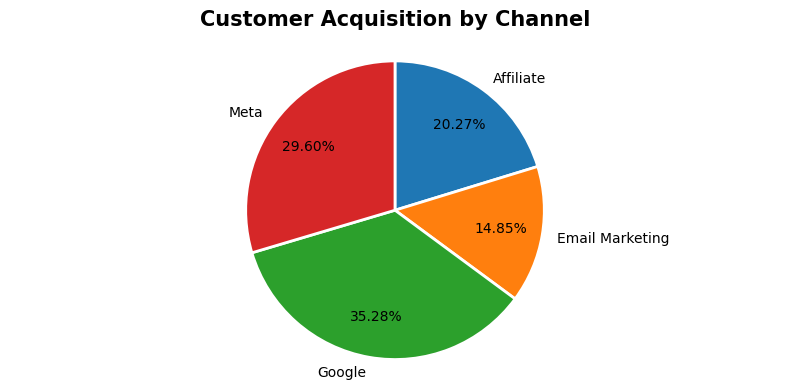

In [5]:
# Customer gained from different channels 

cust = customer_df.groupby(["Acquisition_channel"],as_index = False).agg(Customer_Gained = ("Customer_id","count"))
print(cust)

plt.figure(figsize=(8,4))

plt.pie(
    cust["Customer_Gained"],
    labels=cust["Acquisition_channel"],
    autopct="%1.2f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.72,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10}
)

plt.title(
    "Customer Acquisition by Channel",
    fontsize=15,
    fontweight="semibold",
    pad=15
)

plt.axis("equal")
plt.tight_layout()
plt.show()

**Customer That come to the company are heavily concentrated from Google (35.28%), Meta (29.62%) and so on**

In [6]:
# Customer Gained Over the Month 

customer_df["signup_month"] = customer_df["Signup_date"].dt.to_period("M")

monthly_signup = customer_df.groupby(["signup_month"],as_index = False).agg(Customer_Gained = ("Customer_id","count"))
monthly_signup["signup_month"] = monthly_signup["signup_month"].astype(str)

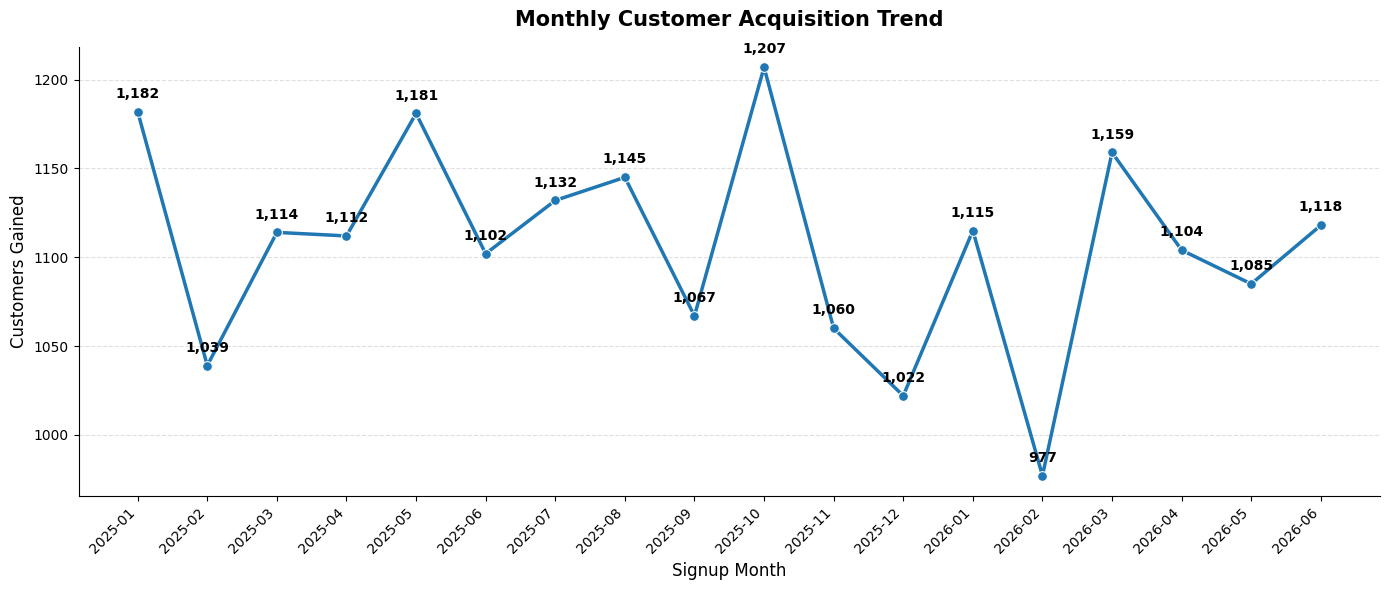

In [7]:
plt.figure(figsize=(14, 6))

ax = sns.lineplot(
    data=monthly_signup,
    x="signup_month",
    y="Customer_Gained",
    marker="o",
    linewidth=2.5,
    markersize=7
)

# Display values on each point
for x, y in zip(monthly_signup["signup_month"], monthly_signup["Customer_Gained"]):
    ax.annotate(
        f"{y:,}",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="semibold"
    )

plt.title(
    "Monthly Customer Acquisition Trend",
    fontsize=15,
    fontweight="semibold",
    pad=15
)

plt.xlabel("Signup Month", fontsize=12)
plt.ylabel("Customers Gained", fontsize=12)

plt.xticks(rotation=45, ha="right")

# Cleaner grid
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.grid(axis="x", visible=False)

# Remove unnecessary borders
sns.despine()

plt.tight_layout()
plt.show()

           Channel  AmountSpend
2           Google     17661647
3             Meta     15738207
0        Affiliate      7171093
1  Email Marketing      1052922


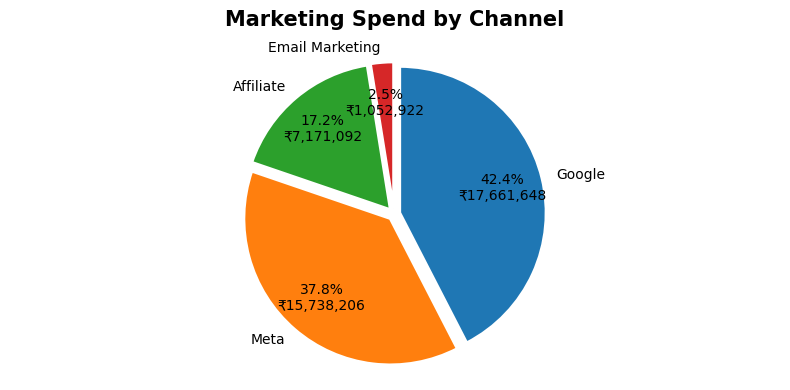

In [36]:
# Amount Spent on Each Channel

amount = (
    marketing_df
    .groupby("Channel", as_index=False)
    .agg(AmountSpend=("Spend_amount", "sum"))
    .sort_values("AmountSpend", ascending=False)
)

print(amount)

explode = [0.04] * len(amount)

plt.figure(figsize=(8,4))

plt.pie(
    amount["AmountSpend"],
    labels=amount["Channel"],
    autopct=lambda p: f"{p:.1f}%\n₹{p * amount['AmountSpend'].sum() / 100:,.0f}",
    startangle=90,
    counterclock=False,
    pctdistance=0.72,
    explode = explode,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={
        "fontsize": 10
    }
)

plt.title(
    "Marketing Spend by Channel",
    fontsize=15,
    fontweight="semibold",
    pad=15
)

plt.axis("equal")
plt.tight_layout()
plt.show()

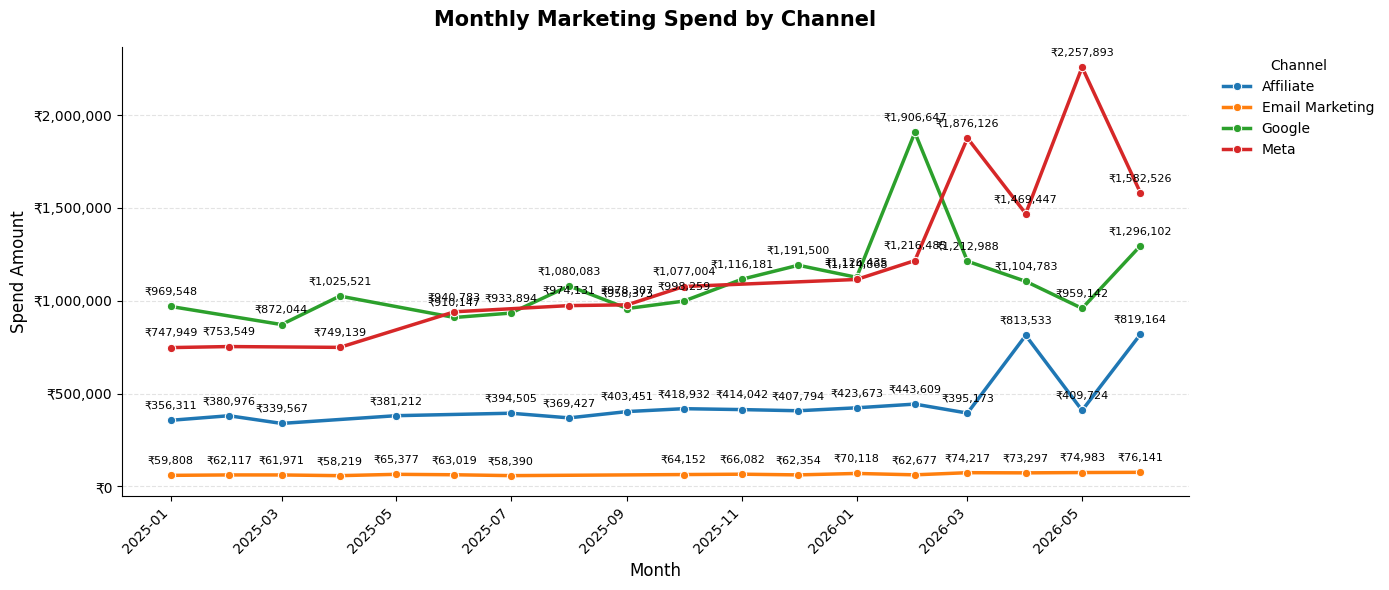

In [9]:
# Amount Spent Over the Months

monthly_spend = (
    marketing_df
    .groupby(["Month", "Channel"], as_index=False)
    .agg(Spend_amount=("Spend_amount", "sum"))
)

import matplotlib.ticker as mticker

plt.figure(figsize=(14, 6))

ax = sns.lineplot(
    data=monthly_spend,
    x="Month",
    y="Spend_amount",
    hue="Channel",
    marker="o",
    linewidth=2.5,
    markersize=6
)

# Format Y-axis
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"₹{x:,.0f}")
)

# Add values to each point
for channel in monthly_spend["Channel"].unique():
    channel_data = monthly_spend[monthly_spend["Channel"] == channel]

    for _, row in channel_data.iterrows():
        ax.annotate(
            f"₹{row['Spend_amount']:,.0f}",
            (row["Month"], row["Spend_amount"]),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

plt.title(
    "Monthly Marketing Spend by Channel",
    fontsize=15,
    fontweight="semibold",
    pad=15
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Spend Amount", fontsize=12)

plt.xticks(rotation=45, ha="right")

# Cleaner grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)
plt.grid(axis="x", visible=False)

# Remove unnecessary borders
sns.despine()

plt.legend(
    title="Channel",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

  Acquisition_channel   Revenue
2              Google  17916650
3                Meta  10015369
1     Email Marketing   7932434
0           Affiliate   5803388


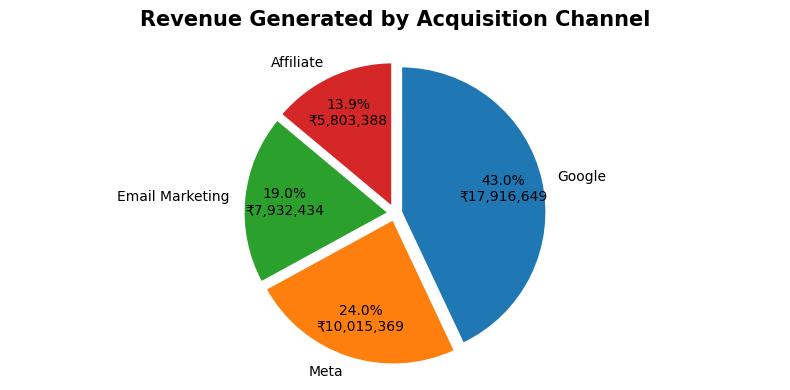

In [39]:
# Revenue Generated from Each Channel 

revenue = order_df[["Customer_id", "Order_amount"]].merge(
    customer_df[["Customer_id", "Acquisition_channel"]],
    on="Customer_id",
    how="inner"
)[["Customer_id", "Acquisition_channel", "Order_amount"]]

rev = revenue.groupby(["Acquisition_channel"],as_index = False).agg(Revenue = ("Order_amount","sum")).sort_values(by = ["Revenue"],ascending = [False])
print(rev)

plt.figure(figsize=(8,4))

# Slightly separate all slices
explode = [0.04] * len(rev)

plt.pie(
    rev["Revenue"],
    labels=rev["Acquisition_channel"],
    autopct=lambda p: (
        f"{p:.1f}%\n"
        f"₹{p * rev['Revenue'].sum() / 100:,.0f}"
    ),
    startangle=90,
    counterclock=False,
    explode=explode,
    pctdistance=0.72,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={
        "fontsize": 10
    }
)

plt.title(
    "Revenue Generated by Acquisition Channel",
    fontsize=15,
    fontweight="semibold",
    pad=15
)

plt.axis("equal")
plt.tight_layout()
plt.show()

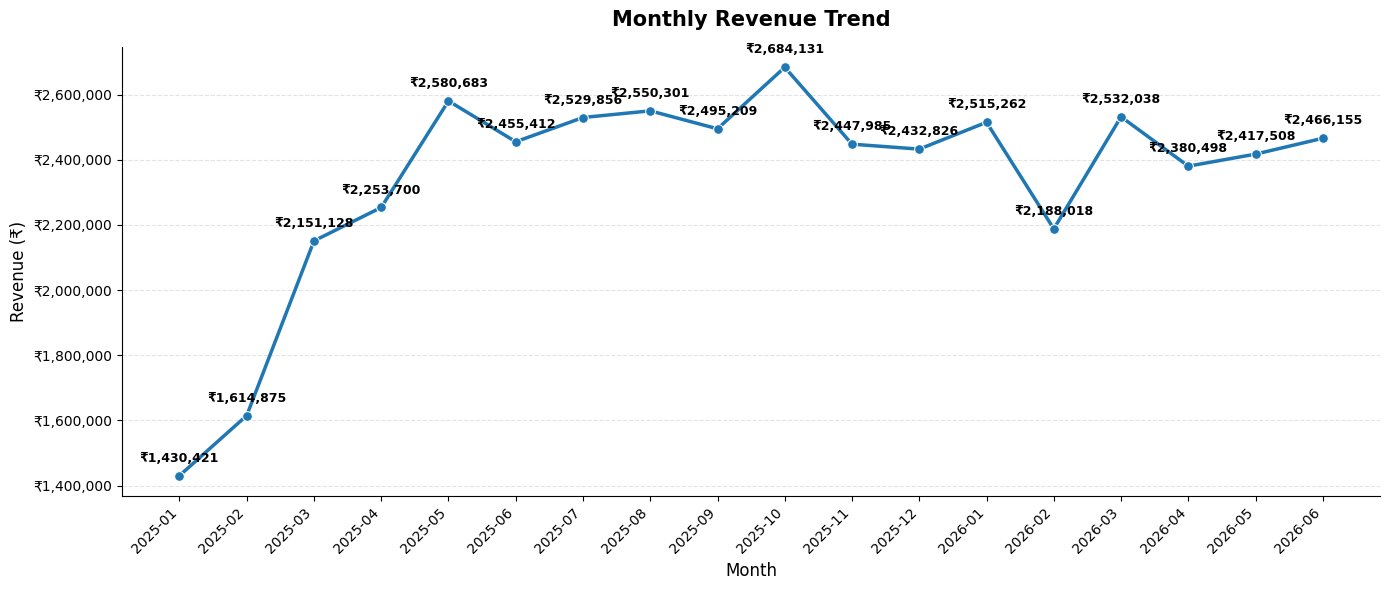

In [11]:
# Monthly Revenue generated Trend 

order_df["Order_month"] = order_df["Order_date"].dt.to_period("M")

monthly_revenue_trend = order_df.groupby(["Order_month"],as_index = False).agg(MonthlyRevenue = ("Order_amount","sum"))
monthly_revenue_trend["Order_month"] = monthly_revenue_trend["Order_month"].astype(str)


plt.figure(figsize=(14, 6))

ax = sns.lineplot(
    data=monthly_revenue_trend,
    x="Order_month",
    y="MonthlyRevenue",
    marker="o",
    linewidth=2.5,
    markersize=7
)

# Add revenue values to each point
for _, row in monthly_revenue_trend.iterrows():
    ax.annotate(
        f"₹{row['MonthlyRevenue']:,.0f}",
        (row["Order_month"], row["MonthlyRevenue"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="semibold"
    )

# Title
plt.title(
    "Monthly Revenue Trend",
    fontsize=15,
    fontweight="semibold",
    pad=15
)

# Axis labels
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (₹)", fontsize=12)

# X-axis formatting
plt.xticks(rotation=45, ha="right")

# Y-axis formatting
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"₹{x:,.0f}")
)

# Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)
plt.grid(axis="x", visible=False)

# Remove unnecessary borders
sns.despine()

plt.tight_layout()
plt.show()

In [12]:
order_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34478 entries, 0 to 34477
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order_id      34478 non-null  object        
 1   Customer_id   34478 non-null  object        
 2   Order_date    34478 non-null  datetime64[ns]
 3   Order_amount  34478 non-null  int64         
 4   Order_month   34478 non-null  period[M]     
dtypes: datetime64[ns](1), int64(1), object(2), period[M](1)
memory usage: 1.3+ MB


In [13]:
# Step 1: count of orders per customer
orders_per_customer = order_df.groupby("Customer_id").size().reset_index(name="order_count")

# Step 2: attach each customer's acquisition channel
orders_per_customer = orders_per_customer.merge(
    customer_df[["Customer_id", "Acquisition_channel"]],
    on="Customer_id"
)

# Step 3: average orders per customer, by channel
avg_orders_by_channel = orders_per_customer.groupby("Acquisition_channel")["order_count"].mean().reset_index()
avg_orders_by_channel = avg_orders_by_channel.sort_values("order_count", ascending=False)

print(avg_orders_by_channel)

  Acquisition_channel  order_count
1     Email Marketing     2.079850
2              Google     1.809324
0           Affiliate     1.603807
3                Meta     1.553636


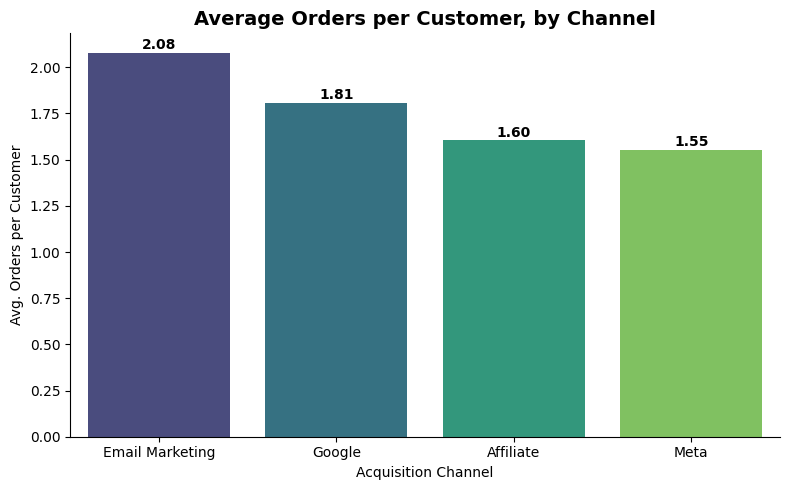

In [14]:
plt.figure(figsize=(8, 5))
sns.barplot(data=avg_orders_by_channel, x="Acquisition_channel", y="order_count", palette="viridis")

plt.title("Average Orders per Customer, by Channel", fontsize=14, fontweight="semibold")
plt.xlabel("Acquisition Channel")
plt.ylabel("Avg. Orders per Customer")

for i, v in enumerate(avg_orders_by_channel["order_count"]):
    plt.text(i, v + 0.02, f"{v:.2f}", ha="center", fontweight="semibold")

sns.despine()
plt.tight_layout()
plt.show()

In [15]:
# Objective 1 
# Calculate Customer Acquisition Cost (CAC) by channel, month-over-month, across the 18-month period.

new_customers = customer_df.groupby(["signup_month","Acquisition_channel"],as_index = False).agg(New_Customers = ("Customer_id","count"))
new_customers.head()

marketing_df["Order_month"] = marketing_df["Month"].dt.to_period("M").astype(str)
new_customers["signup_month"] = new_customers["signup_month"].astype(str)

Cac_df = new_customers.merge(marketing_df,left_on = ["signup_month","Acquisition_channel"],right_on = ["Order_month","Channel"])
Cac_df["CAC"] = np.round(Cac_df["Spend_amount"]/Cac_df["New_Customers"],2)

print(Cac_df[["signup_month","Acquisition_channel","Spend_amount","New_Customers","CAC"]].head(),"\n")

  signup_month Acquisition_channel  Spend_amount  New_Customers      CAC
0      2025-01           Affiliate        356311            250  1425.24
1      2025-01     Email Marketing         59808            158   378.53
2      2025-01              Google        969548            436  2223.73
3      2025-01                Meta        747949            338  2212.87
4      2025-02           Affiliate        380976            220  1731.71 



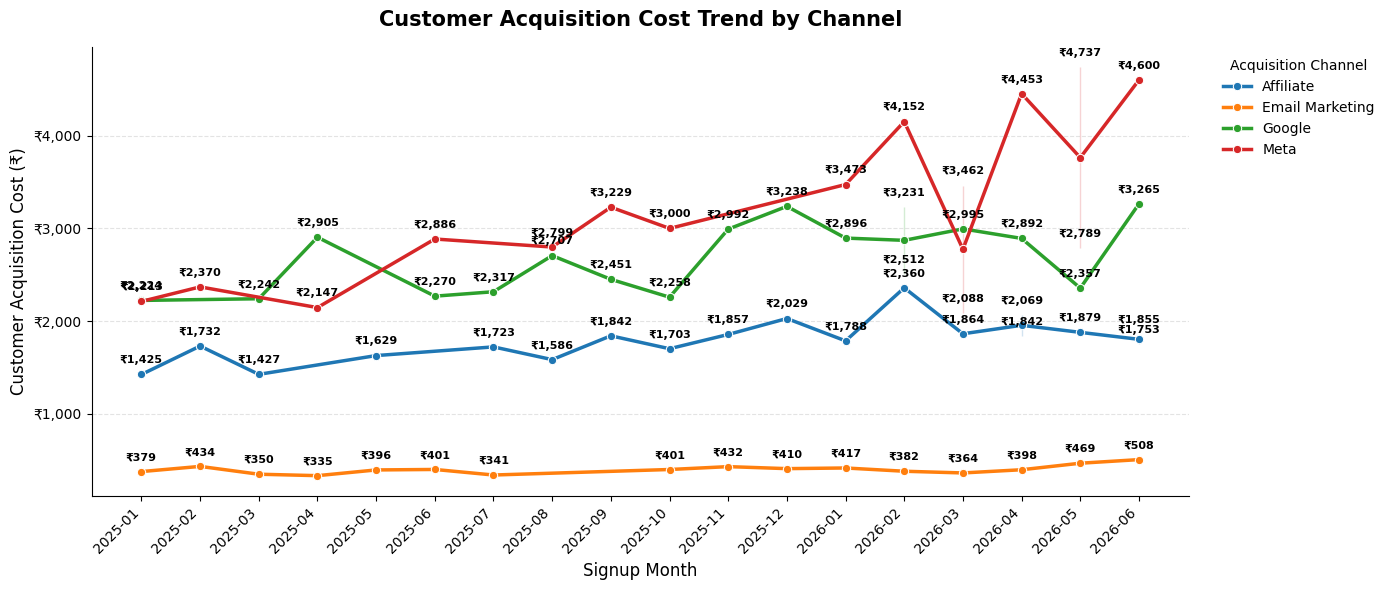

In [16]:
plt.figure(figsize=(14, 6))

ax = sns.lineplot(
    data=Cac_df,
    x="signup_month",
    y="CAC",
    hue="Acquisition_channel",
    marker="o",
    linewidth=2.5,
    markersize=6
)

# Add CAC values to each point
for channel in Cac_df["Acquisition_channel"].unique():
    channel_data = Cac_df[
        Cac_df["Acquisition_channel"] == channel
    ]

    for _, row in channel_data.iterrows():
        ax.annotate(
            f"₹{row['CAC']:,.0f}",
            (row["signup_month"], row["CAC"]),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            fontweight="semibold"
        )

# Title
plt.title(
    "Customer Acquisition Cost Trend by Channel",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Signup Month", fontsize=12)
plt.ylabel("Customer Acquisition Cost (₹)", fontsize=12)

# X-axis
plt.xticks(rotation=45, ha="right")

# Y-axis formatting
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"₹{x:,.0f}")
)

# Grid
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.35
)
plt.grid(axis="x", visible=False)

# Cleaner borders
sns.despine()

# Legend
plt.legend(
    title="Acquisition Channel",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

  Acquisition_channel      Avg_LTV
1     Email Marketing  2694.796466
2              Google  2592.126538
3                Meta  1713.372455
0           Affiliate  1453.145755


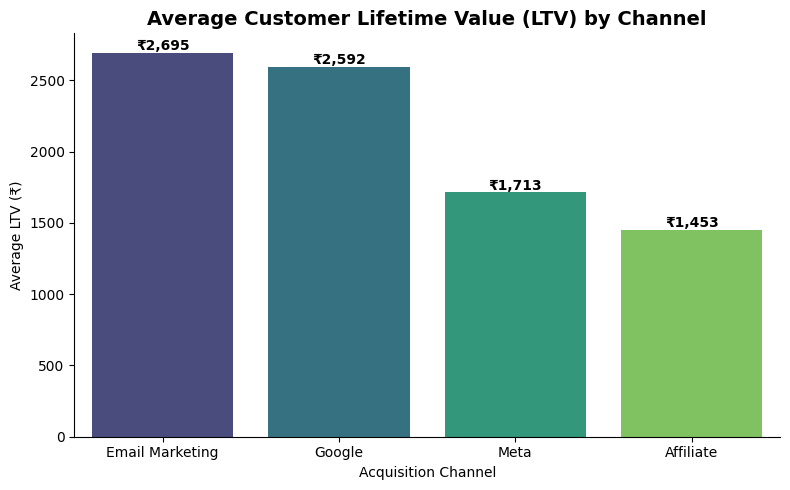

In [17]:
# ------------------------------------------------------------
# Objective 2: Customer Lifetime Value (LTV) by channel
# using a 12-month time horizon
# ------------------------------------------------------------

# Step 1: attach each order to the customer's signup date + channel
order = order_df.merge(
    customer_df[["Customer_id", "Signup_date", "Acquisition_channel"]],
    on="Customer_id"
)

# Step 2: calculate how many days after signup each order happened
order["days_since_signup"] = (order["Order_date"] - order["Signup_date"]).dt.days

# Step 3: keep only orders within the 12-month (365-day) window
WINDOW_DAYS = 365
ltv_orders = order[order["days_since_signup"] <= WINDOW_DAYS]

# Step 4: sum each customer's order amounts within that window = their individual LTV
ltv_per_customer = (
    ltv_orders
    .groupby("Customer_id")["Order_amount"]
    .sum()
    .reset_index(name="LTV")
)

# Step 5: attach channel back to each customer's LTV
ltv_per_customer = ltv_per_customer.merge(
    customer_df[["Customer_id", "Acquisition_channel"]],
    on="Customer_id"
)

# Step 6: average LTV per channel — this is the final answer to Objective 2
ltv_by_channel = (
    ltv_per_customer
    .groupby("Acquisition_channel")["LTV"]
    .mean()
    .reset_index(name="Avg_LTV")
    .sort_values("Avg_LTV", ascending=False)
)

print(ltv_by_channel)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=ltv_by_channel,
    x="Acquisition_channel",
    y="Avg_LTV",
    palette="viridis"
)

for i, v in enumerate(ltv_by_channel["Avg_LTV"]):
    ax.text(i, v + 20, f"₹{v:,.0f}", ha="center", fontweight="semibold")

plt.title("Average Customer Lifetime Value (LTV) by Channel", fontsize=14, fontweight="semibold")
plt.xlabel("Acquisition Channel")
plt.ylabel("Average LTV (₹)")

sns.despine()
plt.tight_layout()
plt.show()

In [18]:
cust_count = customer_df.groupby("Acquisition_channel", as_index=False).agg(
    Total_New_Customers=("Customer_id", "count"))

spend_total = marketing_df.groupby("Channel", as_index=False).agg(
    Total_Spend=("Spend_amount", "sum"))

cac_by_channel = cust_count.merge(spend_total, left_on="Acquisition_channel", right_on="Channel")
cac_by_channel["Avg_CAC"] = cac_by_channel["Total_Spend"] / cac_by_channel["Total_New_Customers"]
cac_by_channel = cac_by_channel.sort_values(by=["Avg_CAC"], ascending=[False])
print(cac_by_channel[["Acquisition_channel", "Total_Spend", "Total_New_Customers", "Avg_CAC"]])

  Acquisition_channel  Total_Spend  Total_New_Customers      Avg_CAC
3                Meta     15738207                 5897  2668.849754
2              Google     17661647                 7028  2513.040268
0           Affiliate      7171093                 4037  1776.342086
1     Email Marketing      1052922                 2959   355.837107


  Acquisition_channel      Avg_LTV      Avg_CAC  LTV_CAC_Ratio  \
0     Email Marketing  2694.796466   355.837107           7.57   
1              Google  2592.126538  2513.040268           1.03   
2                Meta  1713.372455  2668.849754           0.64   
3           Affiliate  1453.145755  1776.342086           0.82   

               Status  
0             Healthy  
1  Weak/Unsustainable  
2        Losing Money  
3        Losing Money  


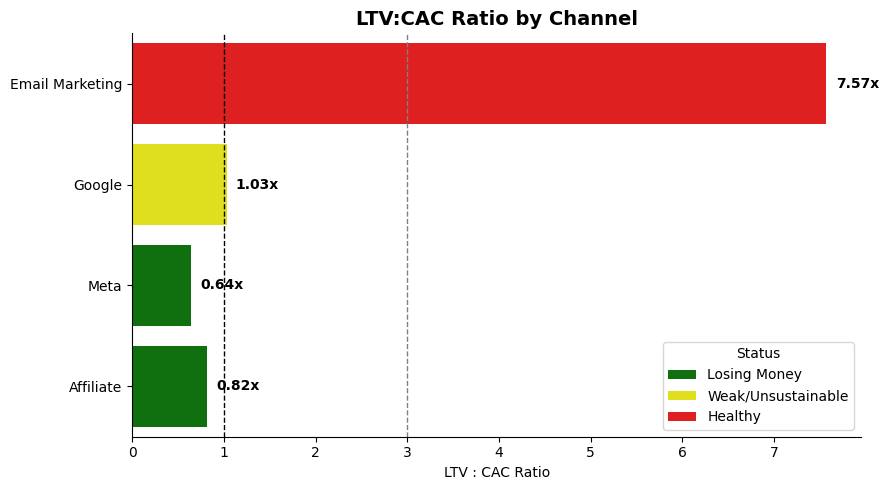

In [19]:
# Objective 3: Compute the LTV:CAC ratio per channel and flag channels performing below a 3:1 target (or below 1:1, where the channel is losing money outright).

summary = ltv_by_channel.merge(cac_by_channel[["Acquisition_channel","Avg_CAC"]], on="Acquisition_channel")

bins = [-float("inf"), 1, 3, float("inf")]
labels = ["Losing Money", "Weak/Unsustainable", "Healthy"]

summary["LTV_CAC_Ratio"] = np.round(summary["Avg_LTV"] / summary["Avg_CAC"], 2)

summary["Status"] = pd.cut(summary["LTV_CAC_Ratio"], bins=bins, labels=labels)
print(summary)

plt.figure(figsize=(9, 5))

colors = summary["Status"].map({
    "Losing Money": "red",
    "Weak/Unsustainable": "yellow",
    "Healthy": "green"
})

ax = sns.barplot(
    data=summary,
    x="LTV_CAC_Ratio",
    y="Acquisition_channel",
    hue = "Status",
    palette=colors.tolist()
)

plt.axvline(1, color="black", linestyle="--", linewidth=1)
plt.axvline(3, color="gray", linestyle="--", linewidth=1)

for i, v in enumerate(summary["LTV_CAC_Ratio"]):
    ax.text(v + 0.1, i, f"{v:.2f}x", va="center", fontweight="semibold")

plt.title("LTV:CAC Ratio by Channel", fontsize=14, fontweight="semibold")
plt.xlabel("LTV : CAC Ratio")
plt.ylabel("")

sns.despine()
plt.tight_layout()
plt.show()

In [20]:
# ------------------------------------------------------------
# Objective 4: Budget allocation vs. where value actually comes from
# ------------------------------------------------------------

total_spend_by_channel = marketing_df.groupby("Channel")["Spend_amount"].sum().reset_index(name="Total_Spend")

order_with_channel = order_df.merge(
    customer_df[["Customer_id", "Acquisition_channel"]],
    on="Customer_id"
)
total_revenue_by_channel = order_with_channel.groupby("Acquisition_channel")["Order_amount"].sum().reset_index(name="Total_Revenue")

allocation = total_spend_by_channel.merge(
    total_revenue_by_channel,
    left_on="Channel",
    right_on="Acquisition_channel"
)

allocation["Spend_Share"] = np.round((allocation["Total_Spend"] / allocation["Total_Spend"].sum()) * 100,2)
allocation["Value_Share"] = np.round((allocation["Total_Revenue"] / allocation["Total_Revenue"].sum()) * 100,2)
allocation["Gap"] = np.round((allocation["Spend_Share"] - allocation["Value_Share"]), 2)

allocation = allocation.sort_values("Gap", ascending=False)
print(allocation)

           Channel  Total_Spend Acquisition_channel  Total_Revenue  \
3             Meta     15738207                Meta       10015369   
0        Affiliate      7171093           Affiliate        5803388   
2           Google     17661647              Google       17916650   
1  Email Marketing      1052922     Email Marketing        7932434   

   Spend_Share  Value_Share    Gap  
3        37.81        24.04  13.77  
0        17.23        13.93   3.30  
2        42.43        43.00  -0.57  
1         2.53        19.04 -16.51  


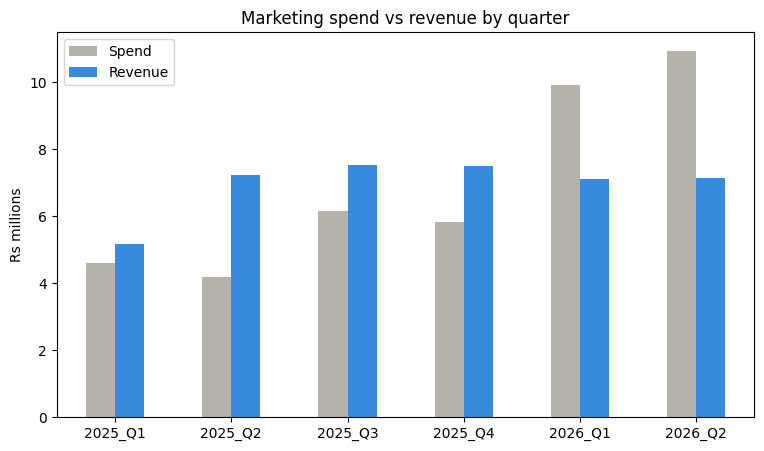

2025_Q1 -> 2026_Q1 | spend growth: 115.5 % | revenue growth: 38.0 %
2025_Q2 -> 2026_Q2 | spend growth: 160.8 % | revenue growth: -1.3 %


In [31]:
order_with_channel = order_df.merge(customer_df[["Customer_id", "Acquisition_channel"]], on="Customer_id")

spend_q = marketing_df.groupby(marketing_df["Month"].dt.to_period("Q").astype(str).str.replace("Q", "_Q"))["Spend_amount"].sum()
rev_q = order_with_channel.groupby(order_with_channel["Order_date"].dt.to_period("Q").astype(str).str.replace("Q", "_Q"))["Order_amount"].sum()

# Bar chart: spend and revenue side by side for every quarter (in millions)
quarters = pd.DataFrame({"Spend": spend_q, "Revenue": rev_q}) / 1000000
quarters.plot(kind="bar", color=["#B4B2A9", "#378ADD"], figsize=(9, 5))
plt.ylabel("Rs millions")
plt.title("Marketing spend vs revenue by quarter")
plt.xticks(rotation=0)
plt.show()

# Same quarter, one year apart
pairs = [("2025_Q1", "2026_Q1"), ("2025_Q2", "2026_Q2")]
for pair in pairs:
    old = pair[0]
    new = pair[1]
    spend_growth = (spend_q[new] - spend_q[old]) / spend_q[old] * 100
    rev_growth = (rev_q[new] - rev_q[old]) / rev_q[old] * 100
    print(old, "->", new, "| spend growth:", round(spend_growth, 1), "% | revenue growth:", round(rev_growth, 1), "%")

Google 2025_Q1 -> 2026_Q1 | spend: 130.57 % | revenue: 42.27 %
Google 2025_Q2 -> 2026_Q2 | spend: 73.58 % | revenue: 8.01 %
Meta 2025_Q1 -> 2026_Q1 | spend: 180.22 % | revenue: 14.05 %
Meta 2025_Q2 -> 2026_Q2 | spend: 214.21 % | revenue: -25.34 %
Affiliate 2025_Q1 -> 2026_Q1 | spend: 17.24 % | revenue: 21.95 %
Affiliate 2025_Q2 -> 2026_Q2 | spend: 435.77 % | revenue: -3.39 %
Email Marketing 2025_Q1 -> 2026_Q1 | spend: 12.57 % | revenue: 81.11 %
Email Marketing 2025_Q2 -> 2026_Q2 | spend: 20.26 % | revenue: 15.99 %


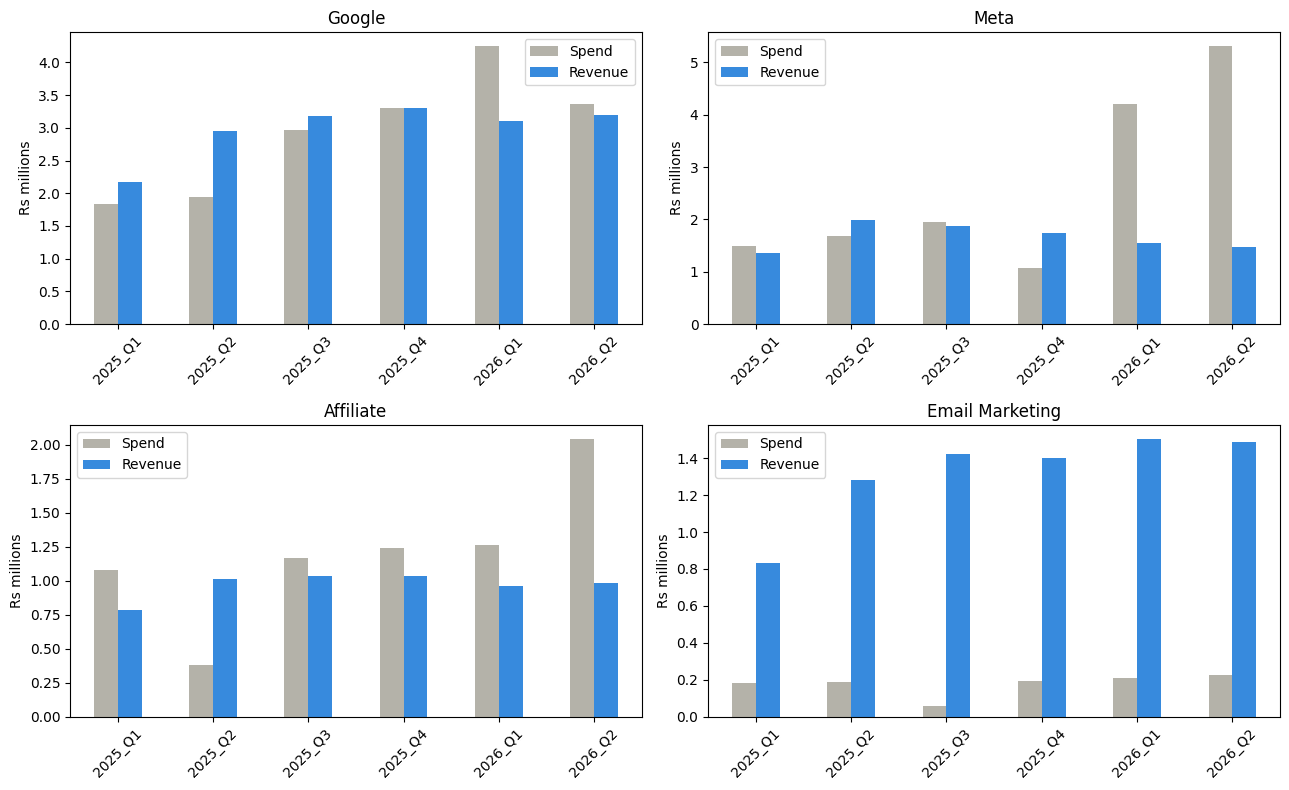

In [34]:
# channels = ["Google", "Meta", "Affiliate", "Email Marketing"]
pairs = [("2025_Q1", "2026_Q1"), ("2025_Q2", "2026_Q2")]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes = axes.flatten()

for i in range(len(channels)):
    ch = channels[i]

    m = marketing_df[marketing_df["Channel"] == ch]
    o = order_with_channel[order_with_channel["Acquisition_channel"] == ch]

    s = m.groupby(m["Month"].dt.to_period("Q").astype(str).str.replace("Q", "_Q"))["Spend_amount"].sum()
    r = o.groupby(o["Order_date"].dt.to_period("Q").astype(str).str.replace("Q", "_Q"))["Order_amount"].sum()

    data = pd.DataFrame({"Spend": s, "Revenue": r}) / 1000000
    data.plot(kind="bar", ax=axes[i], color=["#B4B2A9", "#378ADD"])
    axes[i].set_title(ch)
    axes[i].set_ylabel("Rs millions")
    axes[i].tick_params(axis="x", rotation=45)

    for pair in pairs:
        old = pair[0]
        new = pair[1]
        spend_growth = (s[new] - s[old]) / s[old] * 100
        rev_growth = (r[new] - r[old]) / r[old] * 100
        print(ch, old, "->", new, "| spend:", round(spend_growth, 2), "% | revenue:", round(rev_growth, 2), "%")

plt.tight_layout()
plt.show()

In [22]:
# ------------------------------------------------------------------
# Objective 5 - Where the 20% cut should land 
# ------------------------------------------------------------------

total_spend = allocation["Total_Spend"].sum()
target_cut = total_spend * 0.20

meta_spend = allocation[allocation["Channel"] == "Meta"]["Total_Spend"].values[0]
affiliate_spend = allocation[allocation["Channel"] == "Affiliate"]["Total_Spend"].values[0]

meta_cut = meta_spend * 0.50
affiliate_cut = target_cut - meta_cut

channel_list = []
spend_list = []
cut_list = []
cut_pct_list = []
new_spend_list = []
revenue_lost_list = []

for i in range(len(allocation)):
    channel = allocation.iloc[i]["Channel"]
    spend = allocation.iloc[i]["Total_Spend"]
    revenue = allocation.iloc[i]["Total_Revenue"]

    if channel == "Meta":
        cut = meta_cut
    elif channel == "Affiliate":
        cut = affiliate_cut
    else:
        cut = 0

    # rough estimate: revenue falls in proportion to spend
    revenue_lost = cut * (revenue / spend)

    channel_list.append(channel)
    spend_list.append(round(spend))
    cut_list.append(round(cut))
    cut_pct_list.append(round(cut / spend * 100, 2))
    new_spend_list.append(round(spend - cut))
    revenue_lost_list.append(round(revenue_lost))

cut_plan = pd.DataFrame({
    "Channel": channel_list,
    "Current_spend": spend_list,
    "Cut_percent": cut_pct_list,
    "Cut_amount": cut_list,
    "New_spend": new_spend_list,
    "Revenue_at_risk": revenue_lost_list
})

print(cut_plan)
print("Total cut:", cut_plan["Cut_amount"].sum(), "which is", round(cut_plan["Cut_amount"].sum() / total_spend * 100, 1), "% of spend")
print("Revenue at risk:", cut_plan["Revenue_at_risk"].sum(), "which is", round(cut_plan["Revenue_at_risk"].sum() / allocation["Total_Revenue"].sum() * 100, 1), "% of revenue")

           Channel  Current_spend  Cut_percent  Cut_amount  New_spend  \
0             Meta       15738207        50.00     7869104    7869104   
1        Affiliate        7171093         6.35      455670    6715423   
2           Google       17661647         0.00           0   17661647   
3  Email Marketing        1052922         0.00           0    1052922   

   Revenue_at_risk  
0          5007684  
1           368763  
2                0  
3                0  
Total cut: 8324774 which is 20.0 % of spend
Revenue at risk: 5376447 which is 12.9 % of revenue


## Recommendation

### Where the 20% cut should land: Meta

Meta is the clearest, most defensible candidate for the budget cut, on two independent grounds:

1. **Worst profitability in the dataset** — Meta's LTV:CAC ratio is 0.64, meaning NovaCart loses roughly ₹0.36 for every ₹1 spent acquiring a Meta customer. Meta (0.64) and Affiliate (0.82) sit below the 1:1 break-even line, and Google (1.03) is only just above it, but Meta is the worst of all four. Meta's monthly CAC also trends upward across the 18-month period — consistent with typical ad-fatigue dynamics, though this is a visual read of the monthly table rather than a statistically tested trend.

2. **Most overfunded relative to the value it returns** — Meta consumes 37.81% of total marketing spend but generates only 24.04% of total revenue, a 13.77-percentage-point gap — the largest misallocation of any channel. No other channel shows both problems (weak ratio *and* budget mismatch) simultaneously.

A 20% cut to the total marketing budget, taken primarily from Meta, directly targets the channel doing the most damage to overall ROI, while leaving Google, Affiliate and Email largely untouched.

### Where the freed-up budget should go: Email Marketing

Email is simultaneously the cheapest channel to acquire customers through (CAC ₹356, lowest of all four), the most profitable (LTV:CAC ratio 7.57x — by far the healthiest), and the most underfunded (only 2.53% of budget vs. 19.04% of revenue generated, a −16.51 gap). Reallocating a portion of the Meta cut into Email is the highest-confidence move available in this dataset — it is underinvested in every metric that matters.

### The tradeoff

Cutting Meta isn't without risk. Meta still contributes 24.04% of total revenue today — a full cut, not a partial one, would remove a meaningful revenue stream in the short term, even if that stream is currently unprofitable per customer. Additionally, Email's low spend today (₹1.05M vs. Meta's ₹15.7M) means it likely cannot absorb a large, sudden budget increase efficiently — scaling an underfunded channel too quickly often raises its own CAC over time (diminishing returns on ad spend, smaller total addressable audience for email marketing specifically).

**Recommendation:** cut Meta's spend by 40–50% (not eliminate it entirely). That alone removes roughly 15–19% of total marketing spend. To land exactly on the 20% total cut the brief asks for, combine the Meta cut with a small trim to Affiliate (the second-weakest channel at 0.82 LTV:CAC), rather than trying to squeeze the whole 20% out of Meta alone. Then phase the freed budget into Email gradually over 2–3 months rather than all at once — monitoring whether Email's CAC stays low as spend increases, since that assumption has not been tested at scale in this dataset.

### Note on Google Ads

Google is not a candidate for this cut. Its budget share (42.43%) closely matches its revenue share (43.00%), and its LTV:CAC ratio (1.03) sits right at break-even on a revenue basis. Its issue is a company-wide CAC efficiency problem, not a misallocation problem, and cutting it would not address the actual issue. This is worth flagging separately from the Meta/Email recommendation, since a surface-level read of "Google's ratio is weak too" could wrongly suggest cutting it alongside Meta.

## Assumptions & Limitations

- **LTV horizon:** LTV is measured over a fixed 365-day window from signup, as specified in the brief.
- **LTV denominator:** Average LTV is computed across customers who placed at least one order within that window. Customers acquired but never converted are not included, so reported LTV:CAC ratios should be read as an upper bound rather than a full picture of acquisition efficiency.
- **Revenue-based LTV:** LTV is computed from order revenue, not gross profit. Margin data is not available in this dataset, so LTV:CAC reflects revenue efficiency rather than net profitability.
- **Outlier removal:** 549 outlier orders (1.52% of rows) were removed using the IQR method and treated as data-entry errors.
- **Recommendation is directional:** The Meta cut size (40–50%) is reasoned from LTV:CAC and spend-value gaps, not from a demand model. Email's ability to absorb increased budget at the same CAC is assumed, not tested.

## Conclusion — Answering the Business Question

**Which channels are acquiring customers who generate long-term value, versus which channels are generating cheap, one-time transactions that don't justify their acquisition cost?**

To acquire a single customer, Meta costs around ₹2.7k, Google around ₹2.5k, while Email Marketing only costs around ₹360. But cost alone doesn't tell the full story — when you look at LTV, Email surpasses every other channel. Combining both into the LTV:CAC ratio, Email comes out at 7.57x — meaning for every rupee spent on acquisition, it returns about ₹7.57 in revenue. The other channels are at or below break-even: Google sits right at 1.03x, while Affiliate (0.82) and Meta (0.64) fall below 1x, meaning they return less than one rupee for every rupee spent on acquisition — not a real return.

What's even more striking is that Email only receives about 2.53% of the total marketing budget, despite generating 19.04% of total revenue — while the other channels get roughly proportional spend-to-revenue shares that just aren't actually profitable. That makes Email the only channel that's genuinely beneficial to the business right now. Even Google's 1.03x would turn into a loss once product costs are taken into account.

*Note: LTV in this analysis is revenue-based, not gross-profit-based. Since margin data is not available in this dataset, the LTV:CAC ratios should be read as revenue efficiency, not net profitability.*